In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

data = {
    'Outlook': [
        'Sunny', 'Sunny', 'Overcast', 'Rain',
        'Rain', 'Rain', 'Overcast', 'Sunny',
        'Sunny', 'Rain', 'Sunny', 'Overcast',
        'Overcast', 'Rain'
    ],

    'Temperature': [
        'Hot', 'Hot', 'Hot', 'Mild',
        'Cool', 'Cool', 'Cool', 'Mild',
        'Cool', 'Mild', 'Mild', 'Mild',
        'Hot', 'Mild'
    ],

    'Humidity': [
        'High', 'High', 'High', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'High'
    ],

    'Wind': [
        'Weak', 'Strong', 'Weak', 'Weak',
        'Weak', 'Strong', 'Strong', 'Weak',
        'Weak', 'Weak', 'Strong', 'Strong',
        'Weak', 'Strong'
    ],

    'Play_Tennis': [
        'No', 'No', 'Yes', 'Yes',
        'Yes', 'No', 'Yes', 'No',
        'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'No'
    ]
}

df = pd.DataFrame(data)

print(df)

     Outlook Temperature Humidity    Wind Play_Tennis
0      Sunny         Hot     High    Weak          No
1      Sunny         Hot     High  Strong          No
2   Overcast         Hot     High    Weak         Yes
3       Rain        Mild     High    Weak         Yes
4       Rain        Cool   Normal    Weak         Yes
5       Rain        Cool   Normal  Strong          No
6   Overcast        Cool   Normal  Strong         Yes
7      Sunny        Mild     High    Weak          No
8      Sunny        Cool   Normal    Weak         Yes
9       Rain        Mild   Normal    Weak         Yes
10     Sunny        Mild   Normal  Strong         Yes
11  Overcast        Mild     High  Strong         Yes
12  Overcast         Hot   Normal    Weak         Yes
13      Rain        Mild     High  Strong          No


In [3]:
def gini_impurity(target):

    counts = target.value_counts()
    probabilities = counts / len(target)

    gini = 1 - sum(probabilities ** 2)

    return gini


overall_gini = gini_impurity(df['Play_Tennis'])

print("Overall Gini Impurity:", overall_gini)

Overall Gini Impurity: 0.4591836734693877


In [5]:
def weighted_gini(df, feature, target):

    total = len(df)
    weighted = 0

    print("\nFeature:", feature)

    for value in df[feature].unique():

        subset = df[df[feature] == value]

        gini = gini_impurity(subset[target])

        weight = len(subset) / total

        weighted += weight * gini

        print("\nCategory:", value)
        print("Total records:", len(subset))
        print("Gini impurity:", round(gini, 4))

    print("\nWeighted Gini:", round(weighted, 4))

    return weighted


features = ['Outlook', 'Temperature', 'Humidity', 'Wind']

gini_values = {}

for feature in features:

    gini_values[feature] = weighted_gini(
        df, feature, 'Play_Tennis'
    )


Feature: Outlook

Category: Sunny
Total records: 5
Gini impurity: 0.48

Category: Overcast
Total records: 4
Gini impurity: 0.0

Category: Rain
Total records: 5
Gini impurity: 0.48

Weighted Gini: 0.3429

Feature: Temperature

Category: Hot
Total records: 4
Gini impurity: 0.5

Category: Mild
Total records: 6
Gini impurity: 0.4444

Category: Cool
Total records: 4
Gini impurity: 0.375

Weighted Gini: 0.4405

Feature: Humidity

Category: High
Total records: 7
Gini impurity: 0.4898

Category: Normal
Total records: 7
Gini impurity: 0.2449

Weighted Gini: 0.3673

Feature: Wind

Category: Weak
Total records: 8
Gini impurity: 0.375

Category: Strong
Total records: 6
Gini impurity: 0.5

Weighted Gini: 0.4286


In [7]:
best_feature = min(gini_values, key=gini_values.get)

print("\nGini Values:")

for feature, value in gini_values.items():
    print(feature, ":", round(value, 4))

print("\nBest Root Node:", best_feature)


Gini Values:
Outlook : 0.3429
Temperature : 0.4405
Humidity : 0.3673
Wind : 0.4286

Best Root Node: Outlook


In [9]:
remaining_features = ['Temperature', 'Humidity', 'Wind']

for value in df['Outlook'].unique():

    subset = df[df['Outlook'] == value]

    print("\n==============================")
    print("OUTLOOK =", value)
    print("==============================")

    print("Records:", len(subset))

    if gini_impurity(subset['Play_Tennis']) == 0:

        print("Pure Node")
        print("Prediction:", subset['Play_Tennis'].iloc[0])
        continue

    branch_gini = {}

    for feature in remaining_features:

        branch_gini[feature] = weighted_gini(
            subset, feature, 'Play_Tennis'
        )

    best = min(branch_gini, key=branch_gini.get)

    print("\nBest Feature for", value, ":", best)


OUTLOOK = Sunny
Records: 5

Feature: Temperature

Category: Hot
Total records: 2
Gini impurity: 0.0

Category: Mild
Total records: 2
Gini impurity: 0.5

Category: Cool
Total records: 1
Gini impurity: 0.0

Weighted Gini: 0.2

Feature: Humidity

Category: High
Total records: 3
Gini impurity: 0.0

Category: Normal
Total records: 2
Gini impurity: 0.0

Weighted Gini: 0.0

Feature: Wind

Category: Weak
Total records: 3
Gini impurity: 0.4444

Category: Strong
Total records: 2
Gini impurity: 0.5

Weighted Gini: 0.4667

Best Feature for Sunny : Humidity

OUTLOOK = Overcast
Records: 4
Pure Node
Prediction: Yes

OUTLOOK = Rain
Records: 5

Feature: Temperature

Category: Mild
Total records: 3
Gini impurity: 0.4444

Category: Cool
Total records: 2
Gini impurity: 0.5

Weighted Gini: 0.4667

Feature: Humidity

Category: High
Total records: 2
Gini impurity: 0.5

Category: Normal
Total records: 3
Gini impurity: 0.4444

Weighted Gini: 0.4667

Feature: Wind

Category: Weak
Total records: 3
Gini impurity

In [11]:
from sklearn.preprocessing import LabelEncoder

# Encode categorical columns
df_encoded = df.copy()

encoders = {}

for column in df.columns:

    le = LabelEncoder()

    df_encoded[column] = le.fit_transform(df[column])

    encoders[column] = le


X = df_encoded.drop('Play_Tennis', axis=1)

y = df_encoded['Play_Tennis']


# Create Decision Tree
model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

model.fit(X, y)

print("Decision Tree created successfully!")

Decision Tree created successfully!


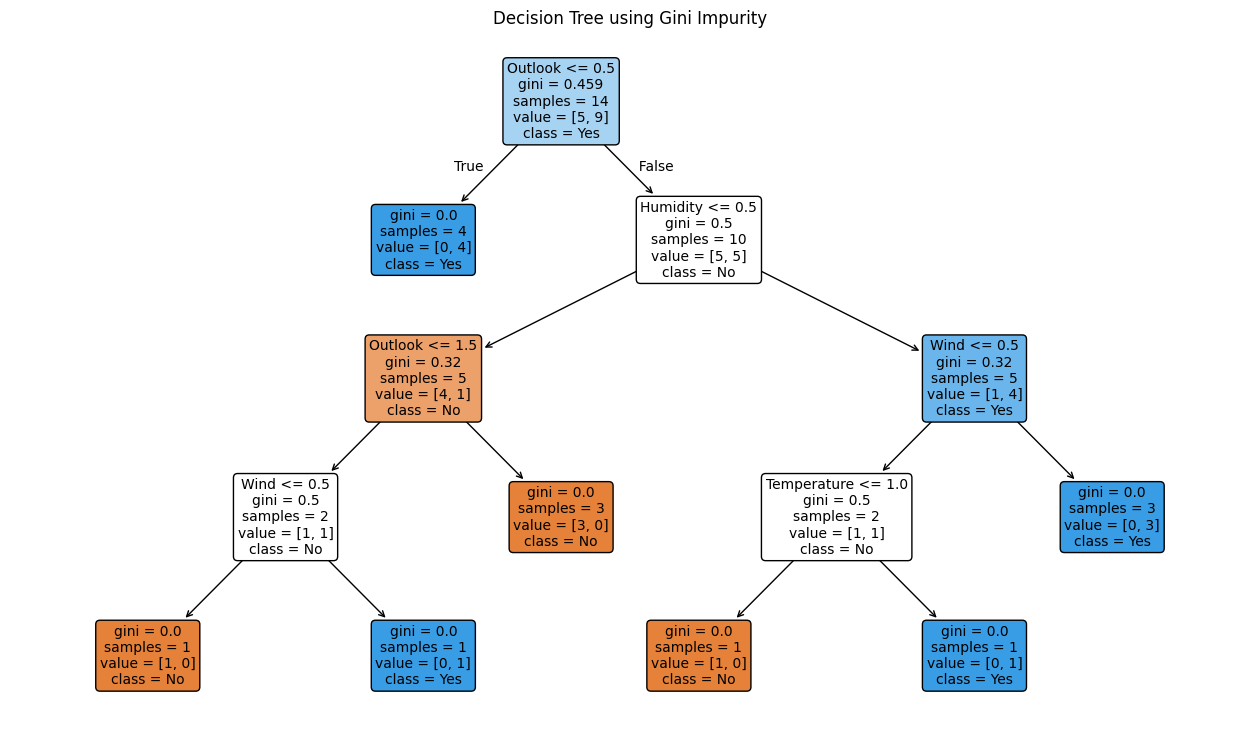

In [13]:
plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=encoders['Play_Tennis'].classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree using Gini Impurity")

plt.show()

In [15]:
new_data = pd.DataFrame({
    'Outlook': ['Sunny'],
    'Temperature': ['Cool'],
    'Humidity': ['High'],
    'Wind': ['Strong']
})

# Encode using the existing encoders
new_encoded = new_data.copy()

for column in new_data.columns:

    new_encoded[column] = encoders[column].transform(
        new_data[column]
    )

prediction = model.predict(new_encoded)

print("Predicted Result:",
      encoders['Play_Tennis'].inverse_transform(prediction)[0])

Predicted Result: No


       Feature  Gini Impurity
0      Outlook       0.342857
2     Humidity       0.367347
3         Wind       0.428571
1  Temperature       0.440476


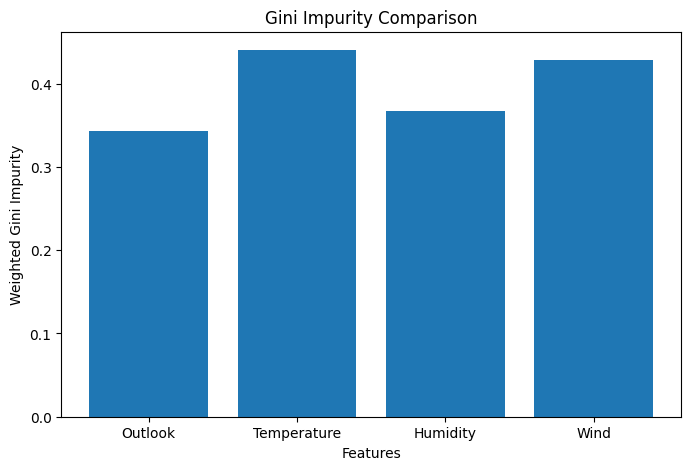

In [17]:
gini_table = pd.DataFrame({
    'Feature': list(gini_values.keys()),
    'Gini Impurity': list(gini_values.values())
})

print(gini_table.sort_values(by='Gini Impurity'))

plt.figure(figsize=(8, 5))

plt.bar(
    gini_table['Feature'],
    gini_table['Gini Impurity']
)

plt.xlabel("Features")
plt.ylabel("Weighted Gini Impurity")
plt.title("Gini Impurity Comparison")

plt.show()